In [273]:
import pymc as pm
import arviz as az
import pandas as pd
from scipy import special
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
plt.style.use('arviz-darkgrid')

In [271]:
study = "v3_prolific"
task = "moteval"
path = f"../outputs/{study}/results_{study}/{task}"
df = pd.read_csv(f'{path}/moteval_lfa.csv')
df = df[["participant_id", "task_status","condition", "3-nb-targets-accuracy", "5-nb-targets-accuracy", "3-nb-targets-correct", "5-nb-targets-correct","3-nb-targets-nb", "5-nb-targets-nb"]]

In [272]:
df

,participant_id,task_status,condition,3-nb-targets-accuracy,5-nb-targets-accuracy,3-nb-targets-correct,5-nb-targets-correct,3-nb-targets-nb,5-nb-targets-nb
0,594,PRE_TEST,zpdes,0.629630,0.407407,17,11,27,27
1,594,POST_TEST,zpdes,0.444444,0.222222,12,6,27,27
2,595,PRE_TEST,zpdes,0.481481,0.074074,13,2,27,27
3,595,POST_TEST,zpdes,0.518519,0.222222,14,6,27,27
4,596,PRE_TEST,baseline,0.296296,0.111111,8,3,27,27
...,...,...,...,...,...,...,...,...,...
141,676,POST_TEST,baseline,0.777778,0.481481,21,13,27,27
142,677,PRE_TEST,baseline,0.444444,0.370370,12,10,27,27
143,677,POST_TEST,baseline,0.814815,0.555556,22,15,27,27
144,679,PRE_TEST,baseline,0.296296,0.111111,8,3,27,27


## Bayesian comparison of posterior
If we set the prior to be a uniform distribution over [0,1] (i.e a Beta with a=b=1) and the likelihood to follow a binomial distribution, the posterior will be a beta of parameters a', b' where:
a' = 
{yi}|π ∼ Prod(Bino(n, π))
π|{yi} ∼ Beta(α + sum(yi), β + m*n − sum(yi)).

In [131]:
from scipy.stats import beta as B

def print_posterior_and_prior(data, condition, print_prior=False):
    alpha, beta, n  = 1, 1, 27
    alpha_posterior  = alpha + data[f"{condition}-correct"].sum() 
    n_posterior = data[f"{condition}-nb"].sum()
    beta_posterior =  beta + n_posterior - data[f"{condition}-correct"].sum()
    rv = B(alpha_posterior, beta_posterior)
    print("Alpha=", alpha_posterior, ", Beta=", beta_posterior, ", m*n =", n_posterior)
    mean, var = rv.stats(moments='mv')
    print(mean, var)
    MLE = data[f"{condition}-correct"].sum() / data[f"{condition}-nb"].sum()
    # Prior plot:
    if print_prior:
        x = np.linspace(rv.ppf(0.01), rv.ppf(0.99), 100)
        plt.plot(x, B.pdf(x, alpha, beta), 'r-', lw=5, alpha=0.6, label='prior pdf')
    # Posterior plot
    x_posterior =  np.linspace(rv.ppf(0.01), rv.ppf(0.99), 100)
    plt.plot(x_posterior, rv.pdf(x_posterior),'b-', lw=5, alpha=0.6, label='posterior pdf')
    plt.axvline(x=MLE, color='red', linestyle='--', label='Maximum likelihood')
    plt.xlabel('x', fontsize=12)
    plt.ylabel('f(x)', fontsize=12)
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.show()
    return rv

Alpha= 977 , Beta= 996 , m*n = 1971
0.49518499746578815 0.00012663465843495216


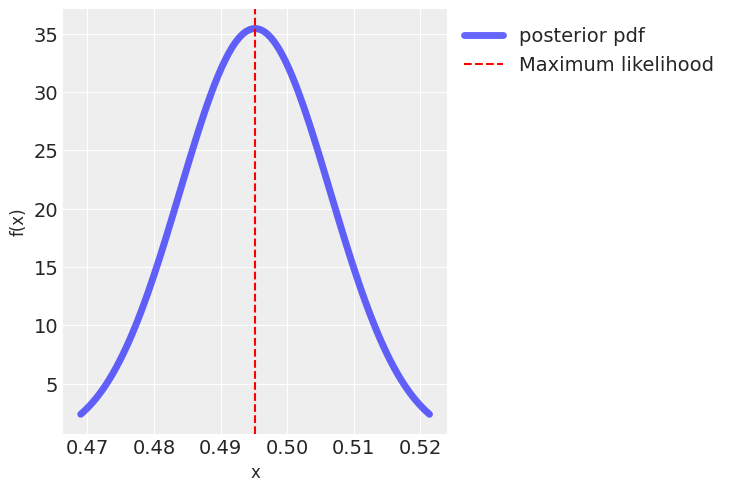

Alpha= 1162 , Beta= 811 , m*n = 1971
0.5889508362899138 0.00012263817057919197


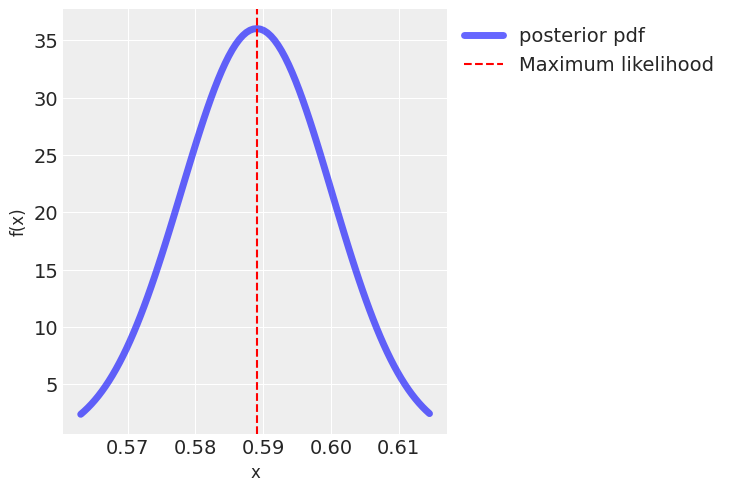

In [134]:
pre = print_posterior_and_prior(df[df["task_status"]=="PRE_TEST"], "3-nb-targets")
post = print_posterior_and_prior(df[df["task_status"]=="POST_TEST"], "3-nb-targets")

There are closed form for the difference but too complicated to implement: https://stats.stackexchange.com/questions/436039/how-to-calculate-the-pdf-of-the-difference-between-two-beta-distributions

(array([1.84152513e-02, 1.10491508e-02, 1.84152513e-02, 5.52457540e-02,
        1.21540659e-01, 1.54688111e-01, 2.79911820e-01, 4.45649082e-01,
        7.43976154e-01, 1.05335238e+00, 1.78259633e+00, 2.46396063e+00,
        3.52836216e+00, 4.86162635e+00, 6.73261589e+00, 8.41208681e+00,
        1.10307356e+01, 1.34578657e+01, 1.62974974e+01, 1.87430428e+01,
        2.11149272e+01, 2.26102456e+01, 2.44591368e+01, 2.48421741e+01,
        2.55566858e+01, 2.47059012e+01, 2.31221896e+01, 2.11738560e+01,
        1.84852293e+01, 1.62901313e+01, 1.36714826e+01, 1.04303984e+01,
        8.90193250e+00, 6.72893284e+00, 5.13785512e+00, 3.82300618e+00,
        2.50079113e+00, 1.75681498e+00, 1.09018288e+00, 7.66074456e-01,
        3.53572826e-01, 3.13059273e-01, 9.20762567e-02, 6.26118545e-02,
        4.41966032e-02, 2.94644021e-02, 2.20983016e-02, 3.68305027e-03,
        0.00000000e+00, 3.68305027e-03]),
 array([0.02855639, 0.03127153, 0.03398667, 0.03670181, 0.03941695,
        0.0421321 , 0.0448

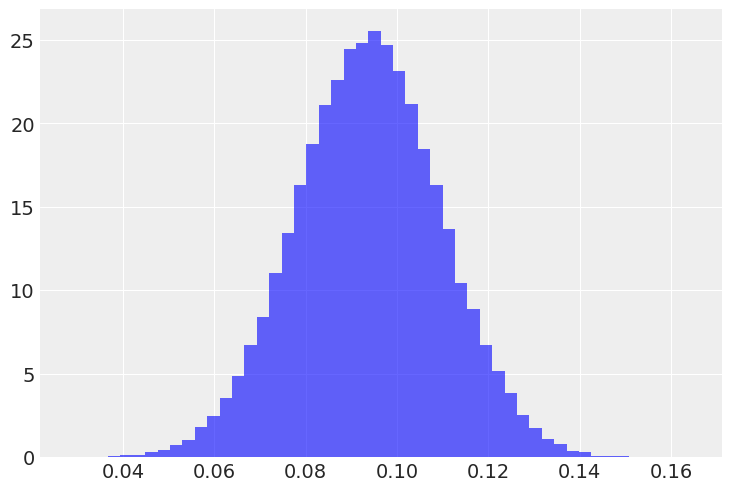

In [122]:
num_samples = 100000
difference = post.rvs(num_samples) - pre.rvs(num_samples)
plt.hist(difference, bins=50, density=True, alpha=0.6, color='blue', label='Difference')

## This is not super helpful as we don't easily get 94% HDI... Let's switch to pymc

In [137]:
import pymc as pm

## Better but...
This is better but here the model is a "pooled" model, let's try to add an individual level. This means that: 
yi | n ~ Bin(πi, n)
πi ~ Beta(

In [143]:
data["3-nb-targets-correct"]

0      17
2      13
4       8
6      19
8       3
       ..
136    13
138    16
140    14
142    12
144     8
Name: 3-nb-targets-correct, Length: 73, dtype: int64

In [202]:
data_pre = df[df["task_status"]=="PRE_TEST"]
data_post = df[df["task_status"]=="POST_TEST"]
#coords = {"observation": data_post.index.values}
with pm.Model() as binomial_regression_model:
    # x = pm.ConstantData("x", data_post["3-nb-targets-correct"])
    # priors
    beta0 = pm.Normal("beta0", mu=0, sigma=1)
    beta1 = pm.Normal("beta1", mu=0, sigma=1)
    # linear model
    mu = beta0 + beta1 * data_pre["3-nb-targets-correct"]
    p = pm.Deterministic("p", pm.math.invlogit(mu))
    # likelihood
    pm.Binomial("y", n=n, p=p, observed=data_post["3-nb-targets-correct"],shape=(1,))

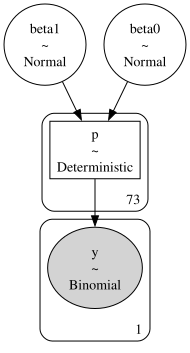

In [203]:
pm.model_to_graphviz(binomial_regression_model)

In [200]:
with binomial_regression_model:
    idata = pm.sample(1000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta0, beta1]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


[]

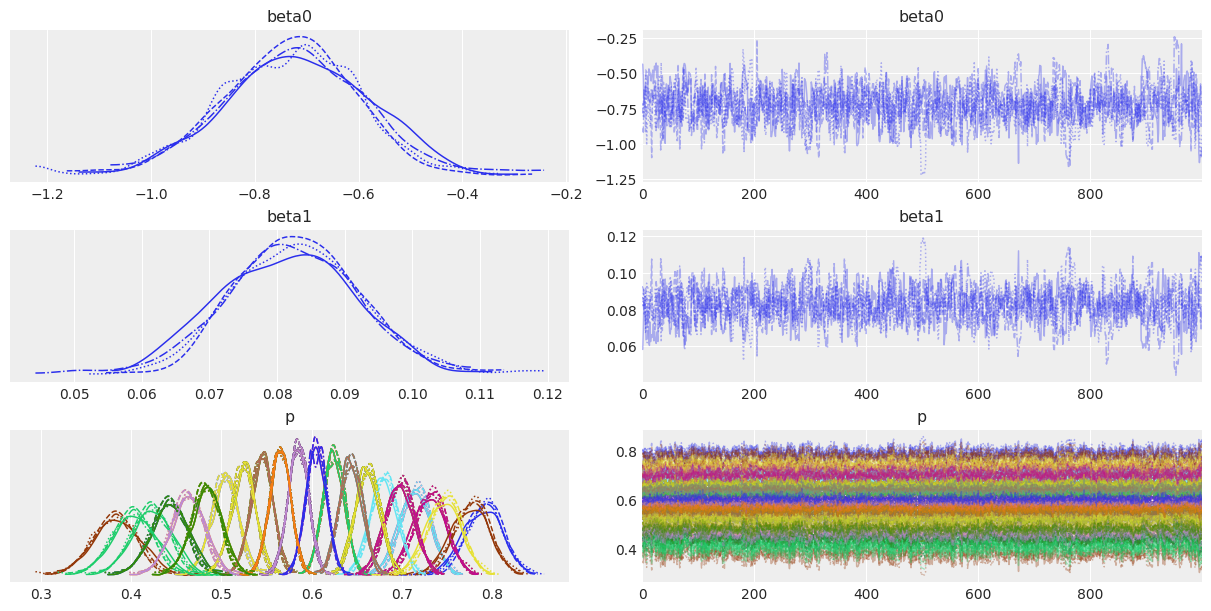

In [201]:
az.plot_trace(idata)
plt.plot()

array([<Axes: title={'center': '94.0% HDI'}>], dtype=object)

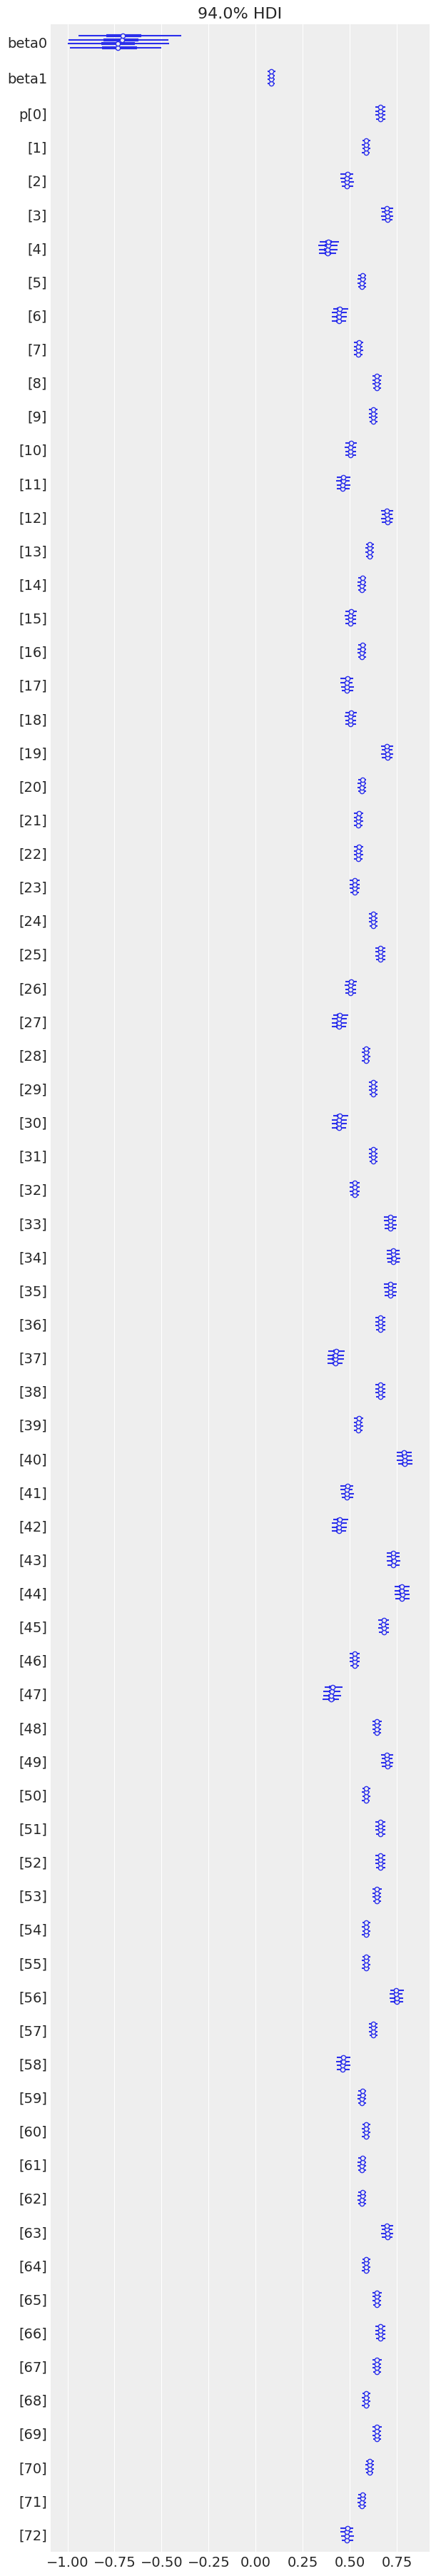

In [169]:
az.plot_forest(idata)

In [171]:
!pipenv install bambi --skip-lock

Installing bambi...
Resolving bambi...
Installing...
Adding bambi to Pipfile's [packages] ...
✔ Installation Succeeded..
⠙ Installing bambi...
Installing dependencies from Pipfile...


In [208]:
import bambi as bmb
bambi_data= pd.DataFrame({"x" : list(df[df["task_status"]=="PRE_TEST"]["3-nb-targets-correct"].values),
                          "y": list(df[df["task_status"]=="POST_TEST"]["3-nb-targets-correct"].values)})
model = bmb.Model("y ~ x", bambi_data)
idata = model.fit(draws=3000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [y_sigma, Intercept, x]


Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 2 seconds.


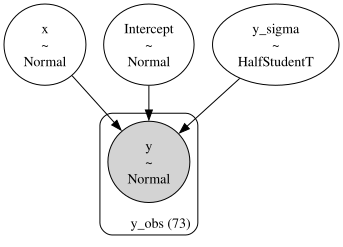

In [209]:
model.graph()

array([[<Axes: title={'center': 'Intercept'}>,
        <Axes: title={'center': 'Intercept'}>],
       [<Axes: title={'center': 'x'}>, <Axes: title={'center': 'x'}>],
       [<Axes: title={'center': 'y_sigma'}>,
        <Axes: title={'center': 'y_sigma'}>]], dtype=object)

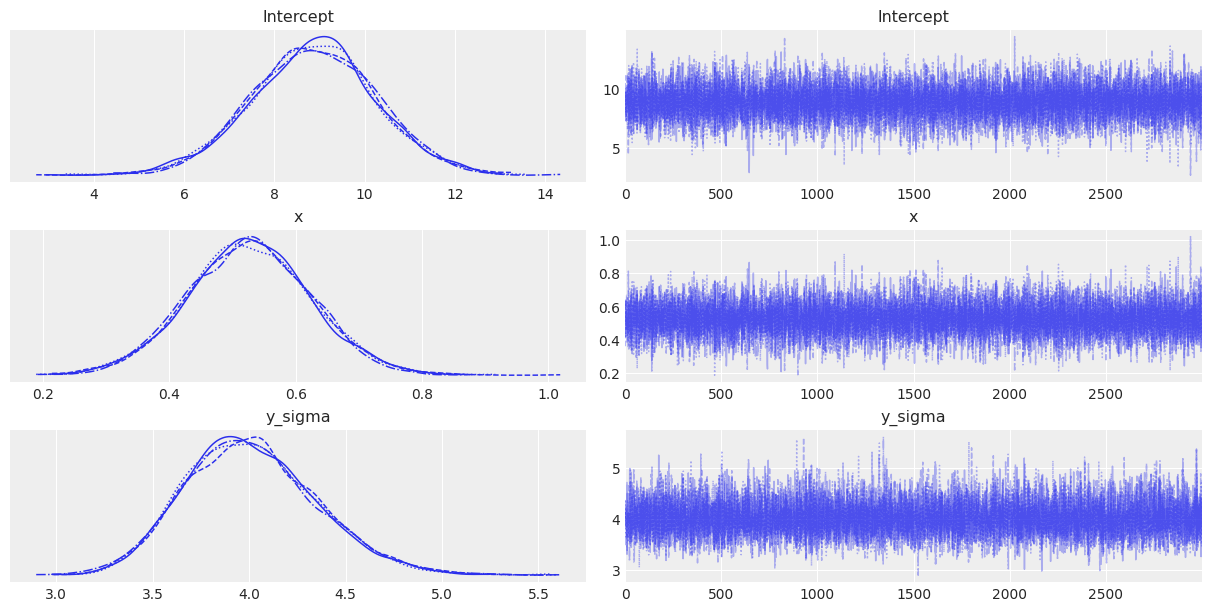

In [178]:
az.plot_trace(idata)

## Ok let's use this and add a group variable
This is better but here the model is a "pooled" model, let's try to add an individual level. This means that: 
yi | n ~ Bin(πi, n)
πi ~ Beta(

In [262]:
conditions = ["zpdes", "baseline"]
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_post = df[df["task_status"]=="POST_TEST"]
data = pd.DataFrame({"y": data_post["3-nb-targets-correct"].values, "x": data_pre["3-nb-targets-correct"].values})
coords = {"condition": conditions}
with pm.Model(coords=coords) as grouped_binomial_regression_model:
    # x = pm.ConstantData("x", data_post["3-nb-targets-correct"])
    # priors
    beta0 = pm.Normal("beta0", mu=0, sigma=1, dims="condition")
    beta1 = pm.Normal("beta1", mu=0, sigma=1, dims="condition")
    # data
    x = pm.MutableData("x", data.x, dims="obs_id")
    g = pm.MutableData("g", data_pre.group_idx, dims="obs_id")
    # linear model
    mu = beta0[g] + beta1[g] * x
    p = pm.Deterministic("p", pm.math.invlogit(mu), dims="obs_id")
    # likelihood
    pm.Binomial("y", n=n, p=p, observed=data.y, dims="obs_id")

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_84415/1020972156.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)


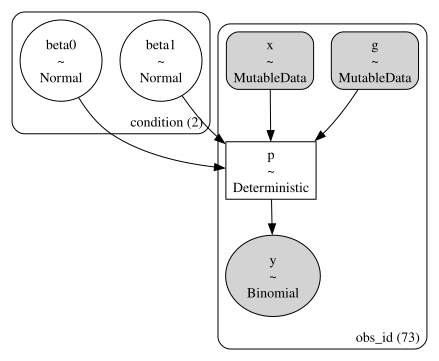

In [264]:
pm.model_to_graphviz(grouped_binomial_regression_model)

In [263]:
with grouped_binomial_regression_model:
    idata = pm.sample(1000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta0, beta1]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


array([[<Axes: title={'center': 'beta0'}>,
        <Axes: title={'center': 'beta0'}>],
       [<Axes: title={'center': 'beta1'}>,
        <Axes: title={'center': 'beta1'}>],
       [<Axes: title={'center': 'p'}>, <Axes: title={'center': 'p'}>]],
      dtype=object)

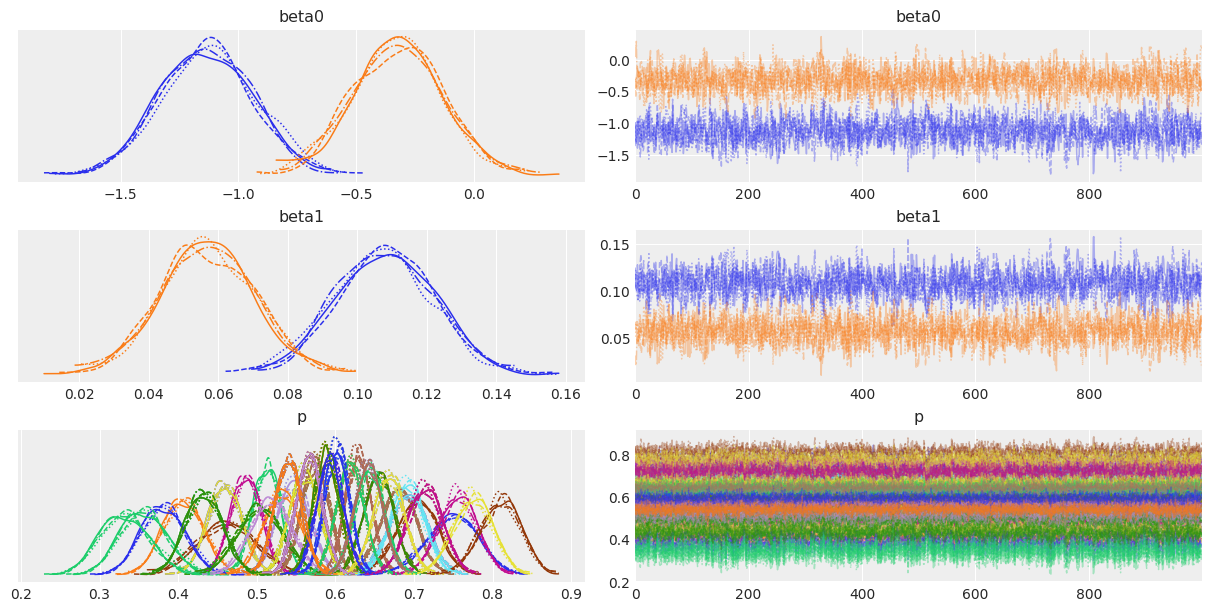

In [254]:
az.plot_trace(idata)

In [270]:
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta0[zpdes],-1.134,0.198,-1.506,-0.777,0.005,0.004,1563.0,1854.0,1.0
beta0[baseline],-0.326,0.192,-0.711,0.021,0.005,0.004,1476.0,1696.0,1.0
beta1[zpdes],0.108,0.014,0.082,0.135,0.000,0.000,1542.0,1635.0,1.0
beta1[baseline],0.057,0.014,0.031,0.084,0.000,0.000,1555.0,1718.0,1.0
p[0],0.656,0.019,0.620,0.692,0.000,0.000,3329.0,2798.0,1.0
...,...,...,...,...,...,...,...,...,...
p[68],0.567,0.016,0.536,0.598,0.000,0.000,5136.0,3157.0,1.0
p[69],0.643,0.017,0.610,0.675,0.000,0.000,3892.0,3023.0,1.0
p[70],0.594,0.016,0.562,0.624,0.000,0.000,5383.0,3173.0,1.0
p[71],0.541,0.017,0.508,0.571,0.000,0.000,4264.0,3134.0,1.0


In [4]:
conditions = ["zpdes", "baseline"]
n = df["3-nb-targets-nb"].unique()[0]
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_post = df[df["task_status"]=="POST_TEST"]
data = pd.DataFrame({"y": data_post["3-nb-targets-correct"].values, "x": data_pre["3-nb-targets-correct"].values})
coords = {"condition": conditions}
with pm.Model(coords=coords) as unpooled:
    # x = pm.ConstantData("x", data_post["3-nb-targets-correct"])
    # priors
    beta = pm.Normal("beta", mu=0, sigma=1, dims="condition")
    # data
    g = pm.MutableData("g", data_pre.group_idx, dims="obs_id")
    # linear model
    p = pm.Deterministic("p", pm.math.invlogit(beta[g]), dims="obs_id")
    # likelihood
    pm.Binomial("y", n=n, p=p, observed=data.y, dims="obs_id")

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2237822624.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 2 seconds.


array([[<Axes: title={'center': 'beta'}>,
        <Axes: title={'center': 'beta'}>],
       [<Axes: title={'center': 'p'}>, <Axes: title={'center': 'p'}>]],
      dtype=object)

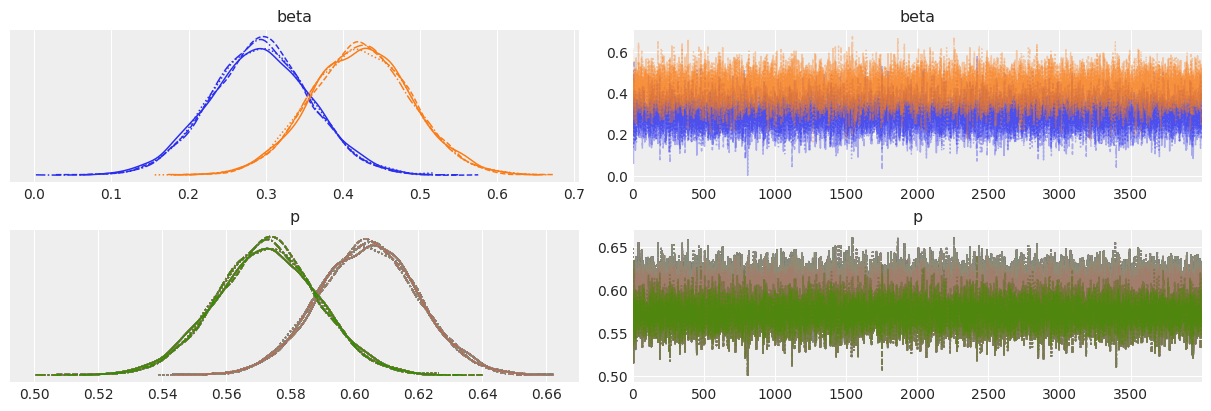

In [5]:
with unpooled:
    trace_unpooled = pm.sample(4000,idata_kwargs = {'log_likelihood': True})
az.plot_trace(trace_unpooled)

In [6]:
conditions = ["zpdes", "baseline"]
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_post = df[df["task_status"]=="POST_TEST"]
data = pd.DataFrame({"y": data_post["3-nb-targets-correct"].values, "x": data_pre["3-nb-targets-correct"].values})
coords = {"condition": conditions}
with pm.Model(coords=coords) as pooled:
    # x = pm.ConstantData("x", data_post["3-nb-targets-correct"])
    # priors
    beta = pm.Normal("beta", mu=0, sigma=1)
    # data
    # g = pm.MutableData("g", data_pre.group_idx, dims="obs_id")
    # linear model
    p = pm.Deterministic("p", pm.math.invlogit(beta))
    # likelihood
    pm.Binomial("y", n=n, p=p, observed=data.y)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2624274392.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 2 seconds.


array([[<Axes: title={'center': 'beta'}>,
        <Axes: title={'center': 'beta'}>],
       [<Axes: title={'center': 'p'}>, <Axes: title={'center': 'p'}>]],
      dtype=object)

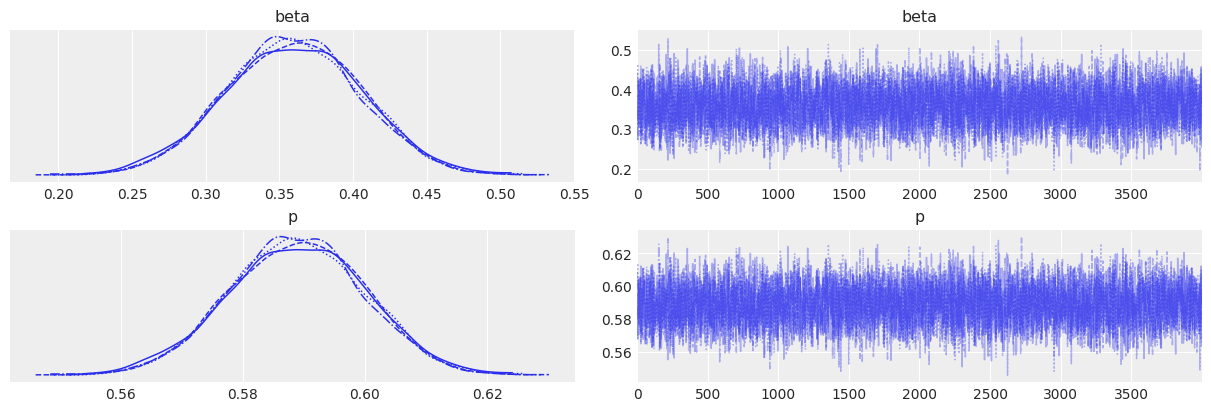

In [7]:
with pooled:
    trace_pooled = pm.sample(4000,idata_kwargs = {'log_likelihood': True})
az.plot_trace(trace_pooled)

In [13]:
# Calculate WAIC
waic_unpooled = pm.waic(trace_unpooled, unpooled)
waic_pooled = pm.waic(trace_pooled, pooled)

# Calculate LOO
loo_unpooled = pm.loo(trace_unpooled, unpooled)
loo_pooled = pm.loo(trace_pooled, pooled)

# Compare the models based on WAIC and LOO
print(f"Unpooled model WAIC: {waic_unpooled.waic}")
print(f"Pooled model WAIC: {waic_pooled.waic}")

print(f"Unpooled model LOO: {loo_unpooled.loo}")
print(f"Pooled model LOO: {loo_pooled.loo}")

/Users/m.adolphe/.local/share/virtualenvs/results_analysis-lNYwU5Fl/lib/python3.10/site-packages/arviz/stats/stats.py:1661: UserWarning: For one or more samples the posterior variance of the log predictive densities exceeds 0.4. This could be indication of WAIC starting to fail. 
See http://arxiv.org/abs/1507.04544 for details
  warnings.warn(
/Users/m.adolphe/.local/share/virtualenvs/results_analysis-lNYwU5Fl/lib/python3.10/site-packages/arviz/stats/stats.py:1661: UserWarning: For one or more samples the posterior variance of the log predictive densities exceeds 0.4. This could be indication of WAIC starting to fail. 
See http://arxiv.org/abs/1507.04544 for details
  warnings.warn(


Unpooled model WAIC: -265.6171673862092
Pooled model WAIC: -264.38783887379816
Unpooled model LOO: -265.6401188920088
Pooled model LOO: -264.3868514238435


## The model that we will use with binary data:

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/988416049.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 2 seconds.


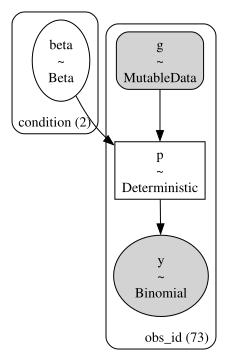

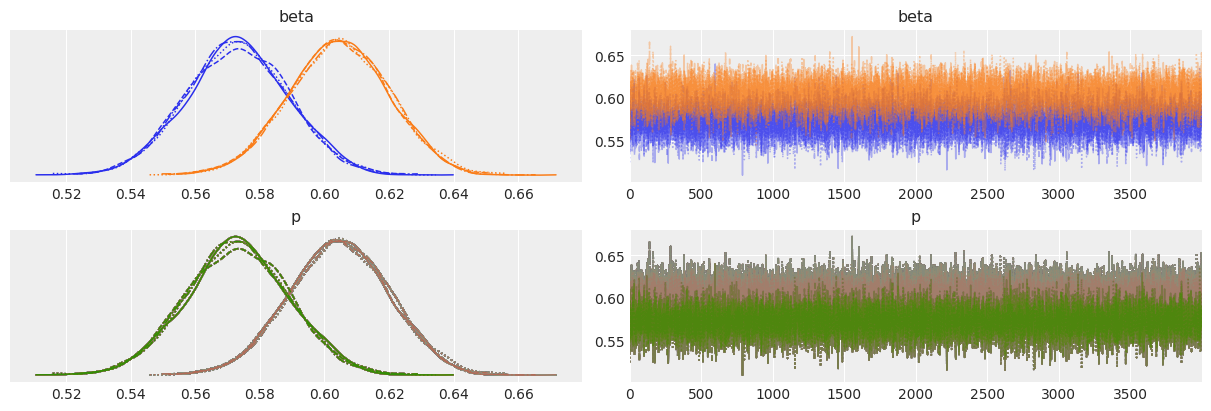

In [17]:
conditions = ["zpdes", "baseline"]
n = df["3-nb-targets-nb"].unique()[0]
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_post = df[df["task_status"]=="POST_TEST"]
data = pd.DataFrame({"y": data_post["3-nb-targets-correct"].values, "x": data_pre["3-nb-targets-correct"].values})
coords = {"condition": conditions}
with pm.Model(coords=coords) as comparison_model:
    # x = pm.ConstantData("x", data_post["3-nb-targets-correct"])
    # priors
    beta = pm.Beta("beta", alpha=1, beta=1, dims="condition")
    # data
    g = pm.MutableData("g", data_pre.group_idx, dims="obs_id")
    # linear model
    p = pm.Deterministic("p", beta[g], dims="obs_id")
    # likelihood
    pm.Binomial("y", n=n, p=p, observed=data.y, dims="obs_id")
with comparison_model:
    trace = pm.sample(4000,idata_kwargs = {'log_likelihood': True})
az.plot_trace(trace)
az.summary(trace)
pm.model_to_graphviz(comparison_model)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/3405641608.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sigma, p_observation]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 4 seconds.


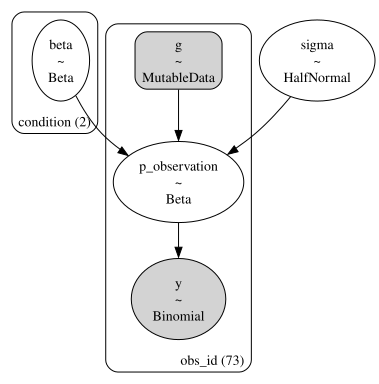

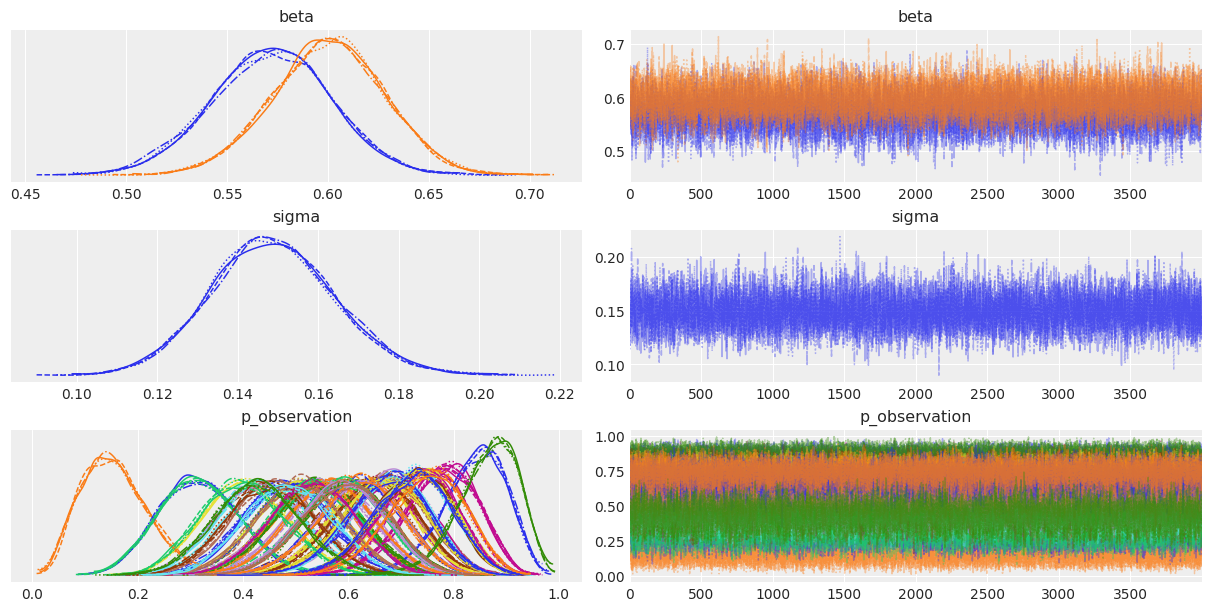

In [22]:
conditions = ["zpdes", "baseline"]
n = df["3-nb-targets-nb"].unique()[0]
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['group_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_post = df[df["task_status"]=="POST_TEST"]
data = pd.DataFrame({"y": data_post["3-nb-targets-correct"].values, "x": data_pre["3-nb-targets-correct"].values})

coords = {"condition": conditions}
with pm.Model(coords=coords) as hierarchical_model:
    
    # Global-level priors (one for each condition)
    beta = pm.Beta("beta", alpha=1, beta=1, dims="condition")
    
    # Data
    g = pm.MutableData("g", data_pre.group_idx, dims="obs_id")
    
    # Introduce a variability term for the local-level
    sigma = pm.HalfNormal('sigma', 0.1)
    
    # Model local-level p's using the global-level p's as mean and sigma as SD
    p_observation = pm.Beta('p_observation', mu=beta[g], sigma=sigma, dims="obs_id")
    
    # Likelihood
    pm.Binomial("y", n=n, p=p_observation, observed=data.y, dims="obs_id")

with hierarchical_model:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace)
az.summary(trace)
pm.model_to_graphviz(hierarchical_model)

array([[<Axes: title={'center': 'p_observation (baseline)'}>,
        <Axes: title={'center': 'p_observation (baseline)'}>]],
      dtype=object)

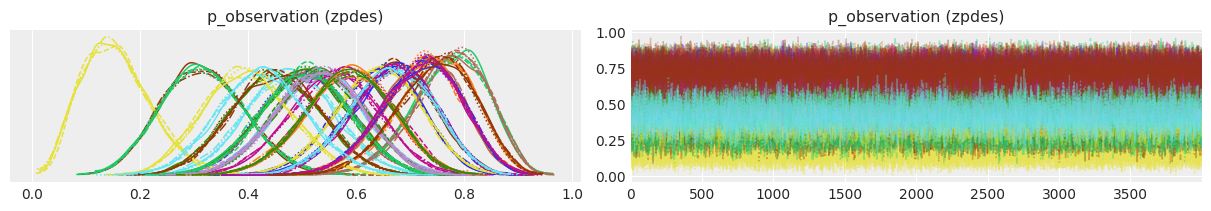

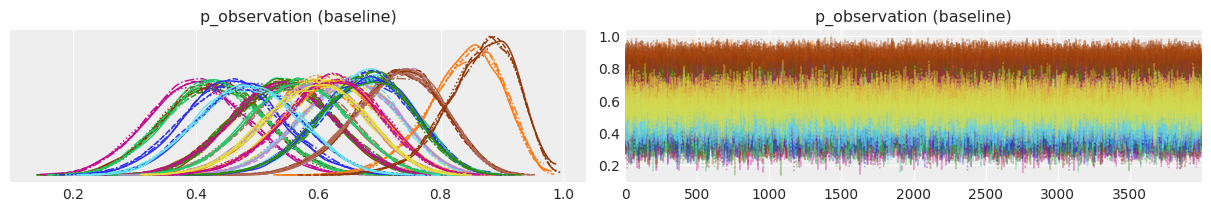

In [33]:
# Extracting posterior for 'zpdes' group (group_idx == 0)
zpdes_posterior = trace.posterior["p_observation"][:,:,data_pre.group_idx == 0]
baseline_posterior = trace.posterior["p_observation"][:,:,data_pre.group_idx == 1]
az.plot_trace({"p_observation (zpdes)": zpdes_posterior})
az.plot_trace({"p_observation (baseline)": baseline_posterior})

In [25]:
print(list(trace.posterior.data_vars))

['beta', 'sigma', 'p_observation']


array([[<Axes: title={'center': 'beta'}>,
        <Axes: title={'center': 'beta'}>]], dtype=object)

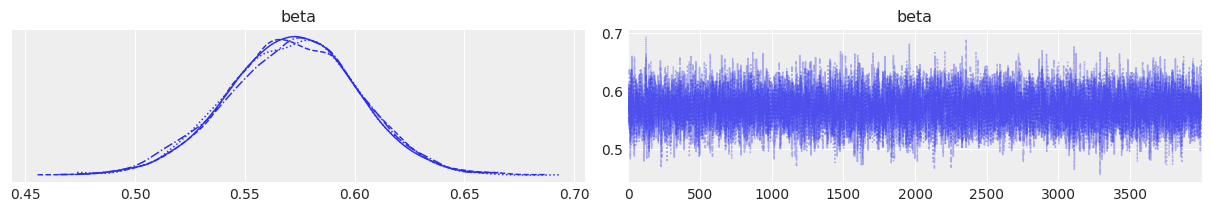

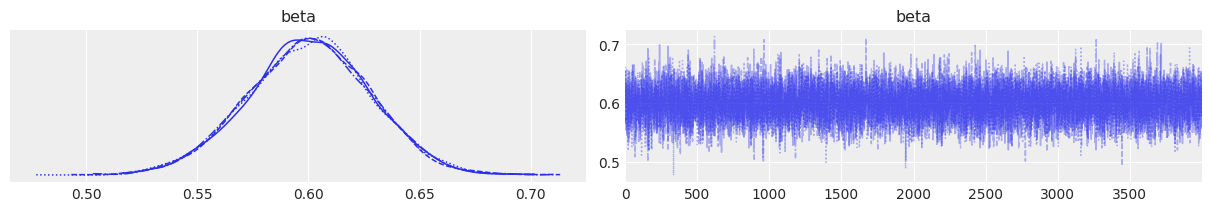

In [48]:
zpdes_beta = trace.posterior["beta"][:,:,0]
az.plot_trace(zpdes_beta)
az.plot_trace(trace.posterior["beta"][:,:,1])

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/3981976909.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/3981976909.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['time_idx'] = 0  # 0 for 'pre'
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/3981976909.py:10: SettingWithCopyWarning: 
A value is trying to be set on a 

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 6 seconds.


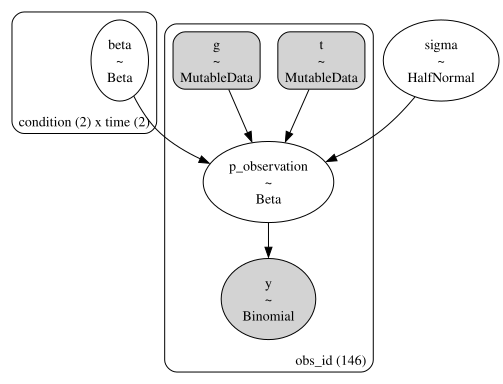

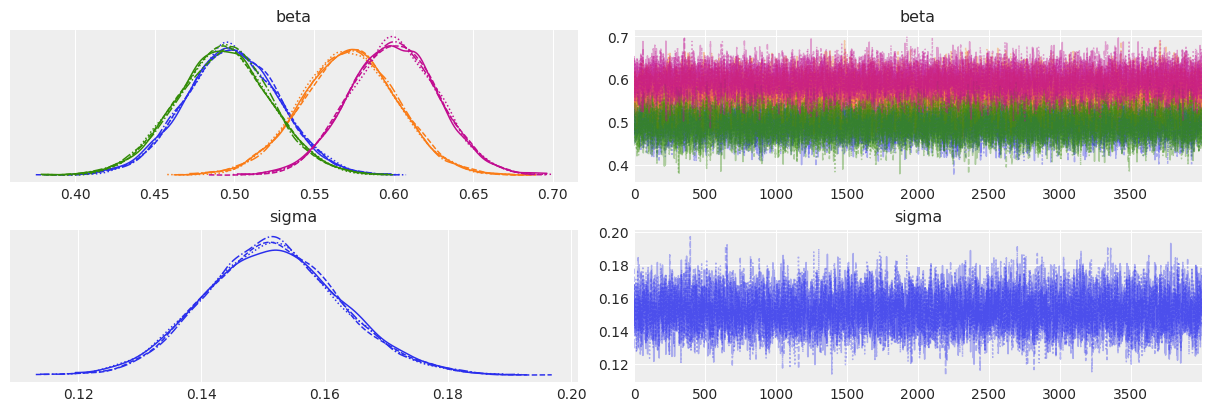

In [50]:
conditions = ["zpdes", "baseline"]
times = ["pre", "post"]
n = df["3-nb-targets-nb"].unique()[0]

# Create 'condition' and 'time' indices
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_pre['time_idx'] = 0  # 0 for 'pre'
data_post = df[df["task_status"]=="POST_TEST"]
data_post['condition_idx'] = (data_post['condition'] == 'zpdes').astype(int)
data_post['time_idx'] = 1  # 1 for 'post'

# Merge data_pre and data_post into one dataframe
data_combined = pd.concat([data_pre, data_post], axis=0)
data = pd.DataFrame({"y": data_combined["3-nb-targets-correct"].values, "x": data_combined["3-nb-targets-correct"].values})

coords = {"condition": conditions, "time": times}
with pm.Model(coords=coords) as hierarchical_model:
    
    # Global-level priors (one for each condition and time)
    beta = pm.Beta("beta", alpha=1, beta=1, dims=("condition", "time"))
    
    # Data
    g = pm.MutableData("g", data_combined.condition_idx, dims="obs_id")
    t = pm.MutableData("t", data_combined.time_idx, dims="obs_id")
    
    # Introduce a variability term for the local-level
    sigma = pm.HalfNormal('sigma', 0.1)
    
    # Model local-level p's using the global-level p's as mean and sigma as SD
    p_observation = pm.Beta('p_observation', mu=beta[g, t], sigma=sigma, dims="obs_id")
    
    # Likelihood
    pm.Binomial("y", n=n, p=p_observation, observed=data.y, dims="obs_id")

with hierarchical_model:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace, var_names=["beta", "sigma"])
az.summary(trace)
pm.model_to_graphviz(hierarchical_model)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2448399841.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2448399841.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['time_idx'] = 0  # 0 for 'pre'
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2448399841.py:10: SettingWithCopyWarning: 
A value is trying to be set on a 

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 8 seconds.


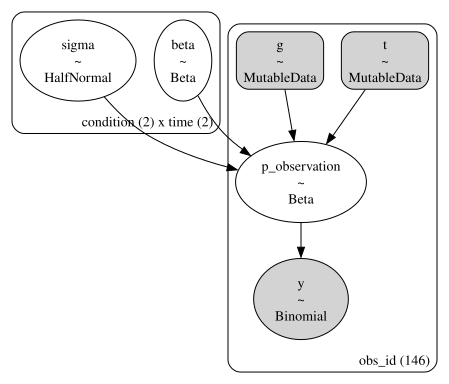

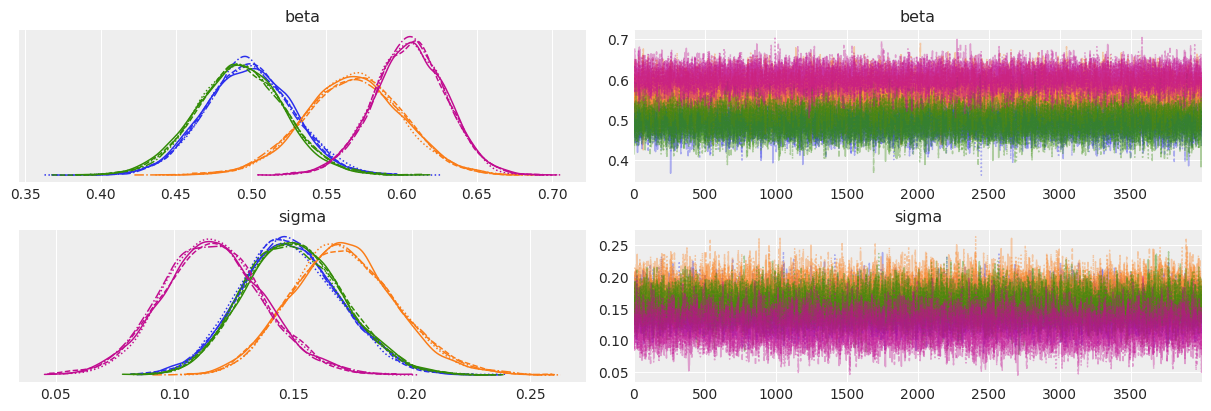

In [51]:
conditions = ["zpdes", "baseline"]
times = ["pre", "post"]
n = df["3-nb-targets-nb"].unique()[0]

# Create 'condition' and 'time' indices
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_pre['time_idx'] = 0  # 0 for 'pre'
data_post = df[df["task_status"]=="POST_TEST"]
data_post['condition_idx'] = (data_post['condition'] == 'zpdes').astype(int)
data_post['time_idx'] = 1  # 1 for 'post'

# Merge data_pre and data_post into one dataframe
data_combined = pd.concat([data_pre, data_post], axis=0)
data = pd.DataFrame({"y": data_combined["3-nb-targets-correct"].values, "x": data_combined["3-nb-targets-correct"].values})

coords = {"condition": conditions, "time": times}
with pm.Model(coords=coords) as hierarchical_model:
    
    # Global-level priors (one for each condition and time)
    beta = pm.Beta("beta", alpha=1, beta=1, dims=("condition", "time"))
    
    # Data
    g = pm.MutableData("g", data_combined.condition_idx, dims="obs_id")
    t = pm.MutableData("t", data_combined.time_idx, dims="obs_id")
    
    # Introduce a variability term for the local-level
    sigma = pm.HalfNormal('sigma', 0.1, dims=("condition", "time"))
    
    # Model local-level p's using the global-level p's as mean and sigma as SD
    p_observation = pm.Beta('p_observation', mu=beta[g, t], sigma=sigma[g, t], dims="obs_id")
    
    # Likelihood
    pm.Binomial("y", n=n, p=p_observation, observed=data.y, dims="obs_id")

with hierarchical_model:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace, var_names=["beta", "sigma"])
az.summary(trace)
pm.model_to_graphviz(hierarchical_model)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2116576715.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2116576715.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['time_idx'] = 0  # 0 for 'pre'
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/2116576715.py:10: SettingWithCopyWarning: 
A value is trying to be set on a 

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 8 seconds.


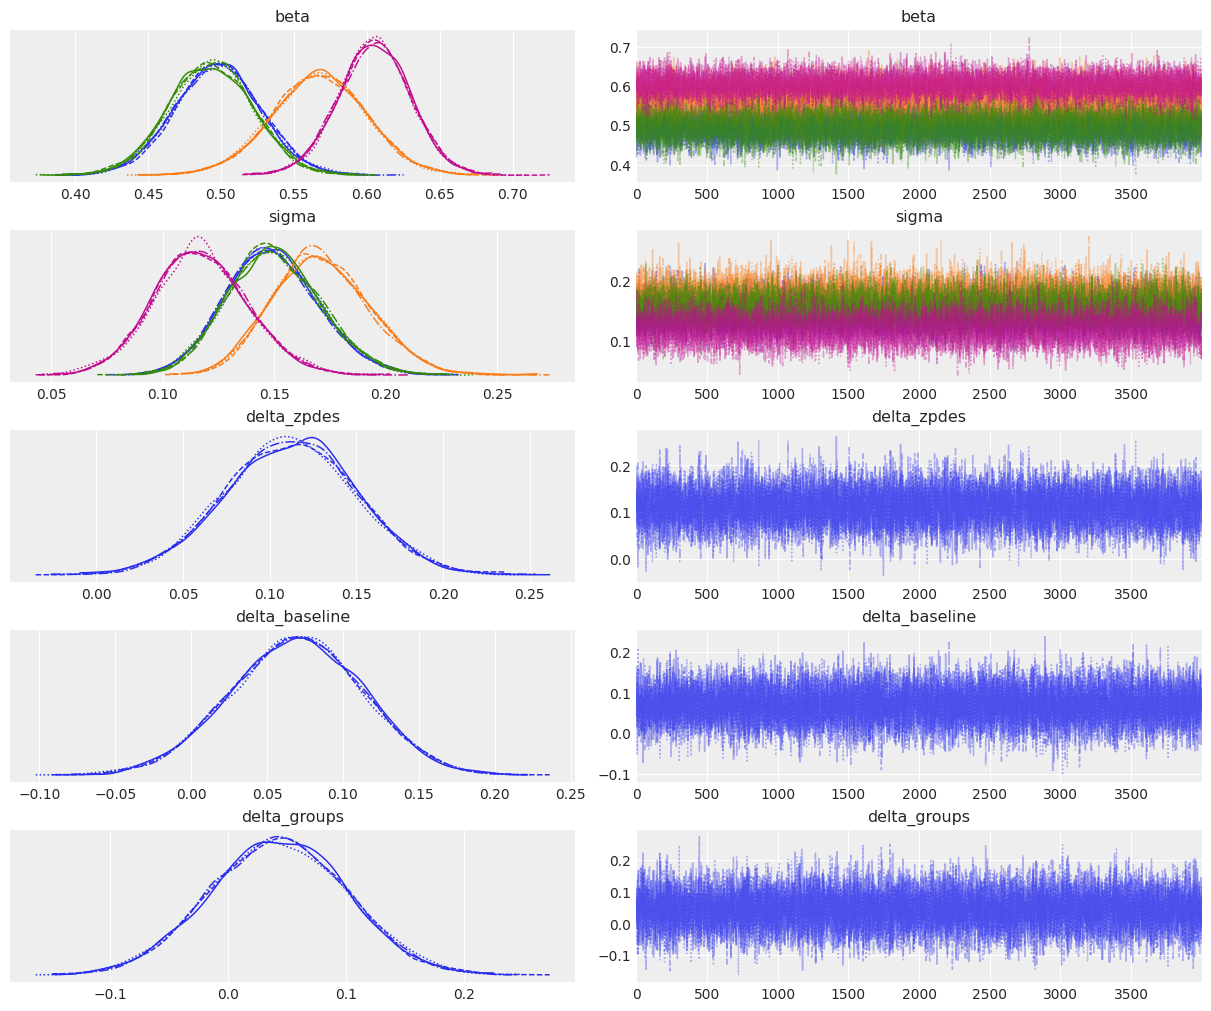

In [256]:
conditions = ["zpdes", "baseline"]
times = ["pre", "post"]
n = df["3-nb-targets-nb"].unique()[0]

# Create 'condition' and 'time' indices
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_pre['time_idx'] = 0  # 0 for 'pre'
data_post = df[df["task_status"]=="POST_TEST"]
data_post['condition_idx'] = (data_post['condition'] == 'zpdes').astype(int)
data_post['time_idx'] = 1  # 1 for 'post'
data_pre = data_pre.set_index('participant_id')
data_post = data_post.set_index('participant_id')

# Merge data_pre and data_post into one dataframe
data_combined = pd.concat([data_pre, data_post], axis=0)
data = pd.DataFrame({"y": data_combined["3-nb-targets-correct"].values, "x": data_combined["3-nb-targets-correct"].values})

coords = {"condition": conditions, "time": times}
with pm.Model(coords=coords) as hierarchical_model:
    
    # Global-level priors (one for each condition and time)
    beta = pm.Beta("beta", alpha=1, beta=1, dims=("condition", "time"))
    
    # Deterministic parameters for the differences
    delta_zpdes = pm.Deterministic("delta_zpdes", beta[1, 1] - beta[1, 0])  # post - pre for zpdes
    delta_baseline = pm.Deterministic("delta_baseline", beta[0, 1] - beta[0, 0])  # post - pre for baseline
    delta_groups = pm.Deterministic("delta_groups", delta_zpdes - delta_baseline)
    
    # Data
    g = pm.MutableData("g", data_combined.condition_idx, dims="obs_id")
    t = pm.MutableData("t", data_combined.time_idx, dims="obs_id")
    
    # Introduce a variability term for the local-level
    sigma = pm.HalfNormal('sigma', 0.1, dims=("condition", "time"))
    
    # Model local-level p's using the global-level p's as mean and sigma as SD
    p_observation = pm.Beta('p_observation', mu=beta[g, t], sigma=sigma[g, t], dims="obs_id")
    
    # Likelihood
    pm.Binomial("y", n=n, p=p_observation, observed=data.y, dims="obs_id")

with hierarchical_model:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace, var_names=["beta", "sigma", "delta_zpdes", "delta_baseline", "delta_groups"])
az.summary(trace)
pm.model_to_graphviz(hierarchical_model)
plt.show()

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/583984378.py:80: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


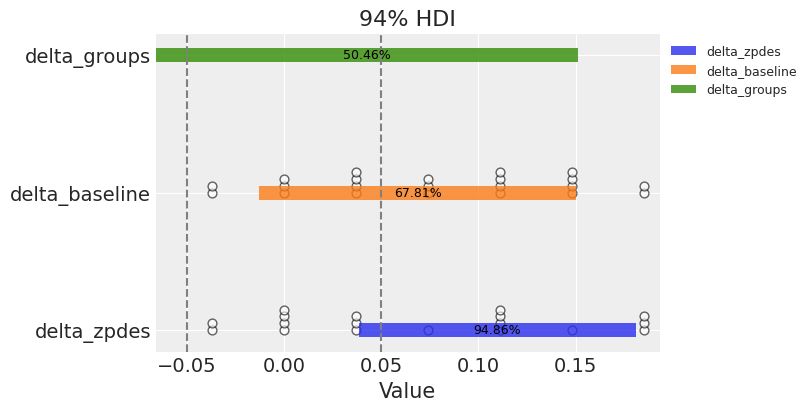

In [269]:
plt.close()
plt.figure(figsize=(8, 4))

rope_start, rope_end = -0.05, 0.05

# For individuals: 
deltas = (data_post['3-nb-targets-correct']- data_pre['3-nb-targets-correct'])/27

# Scatter plot positions
y_positions = {
    "zpdes": "delta_zpdes",
    "baseline": "delta_baseline"
}

# Probabilities for each delta to be in the ROPE
p_delta_zpdes = 1 - np.mean((trace.posterior['delta_zpdes'] > rope_start) & (trace.posterior['delta_zpdes'] < rope_end))
p_delta_baseline = 1 - np.mean((trace.posterior['delta_baseline'] > rope_start) & (trace.posterior['delta_baseline'] < rope_end))
p_delta_groups = 1 - np.mean((trace.posterior['delta_groups'] > rope_start) & (trace.posterior['delta_groups'] < rope_end))

# Compute the HDIs:
# 1. Extract the values
delta_zpdes_values = trace.posterior["delta_zpdes"].values.flatten()
delta_baseline_values = trace.posterior["delta_baseline"].values.flatten()
delta_groups_values = trace.posterior["delta_groups"].values.flatten()

# 2. Compute the 94% HDI for these values
hdi_delta_zpdes = az.hdi(delta_zpdes_values, hdi_prob=0.94)
hdi_delta_baseline = az.hdi(delta_baseline_values, hdi_prob=0.94)
hdi_delta_groups = az.hdi(delta_groups_values, hdi_prob=0.94)



# Scatter plots
def jitter_yvals(y_base, val_x, existing, amount=0.05):
    """Shifts y value slightly above if it already exists in the set"""
    if val_x in existing:
        existing[val_x] += amount
    else:
        existing[val_x] = y_base
    return existing[val_x]

# Set Y-coordinates for each condition
y_coords = {
    'zpdes': 0,
    'baseline': 1
}

# Overlay individual deltas
for condition, group in deltas.groupby(data_pre['condition_idx']):
    condition_name = 'zpdes' if condition == 1 else 'baseline'
    existing_x = {}
    y_base = y_coords[condition_name]
    y_vals = [jitter_yvals(y_base, val_x, existing_x) for val_x in group]
    plt.scatter(group.values, y_vals, alpha=0.6, edgecolors='k', color='white', s=40)

# Plot the HDIs
plt.barh("delta_zpdes", width=(hdi_delta_zpdes[1] - hdi_delta_zpdes[0]),
         left=hdi_delta_zpdes[0], height=0.1, align='center', alpha=0.8, label='delta_zpdes')
plt.barh("delta_baseline", width=(hdi_delta_baseline[1] - hdi_delta_baseline[0]),
         left=hdi_delta_baseline[0], height=0.1, align='center', alpha=0.8, label='delta_baseline')
plt.barh("delta_groups", width=(hdi_delta_groups[1] - hdi_delta_groups[0]),
         left=hdi_delta_groups[0], height=0.1, align='center', alpha=0.8, label='delta_groups')
    
# Displaying the probabilities in the middle of the bars
mid_zpdes = hdi_delta_zpdes[0] + (hdi_delta_zpdes[1] - hdi_delta_zpdes[0]) / 2
mid_baseline = hdi_delta_baseline[0] + (hdi_delta_baseline[1] - hdi_delta_baseline[0]) / 2
mid_groups = hdi_delta_groups[0] + (hdi_delta_groups[1] - hdi_delta_groups[0]) / 2

plt.text(mid_zpdes, "delta_zpdes", f"{p_delta_zpdes:.2%}", ha='center', va='center', color='black', fontsize=9)
plt.text(mid_baseline, "delta_baseline", f"{p_delta_baseline:.2%}", ha='center', va='center', color='black', fontsize=9)
plt.text(mid_groups, "delta_groups", f"{p_delta_groups:.2%}", ha='center', va='center', color='black', fontsize=9)


# Adding vertical lines
plt.axvline(x=rope_start, color='grey', linestyle='--')
plt.axvline(x=rope_end, color='grey', linestyle='--')
plt.xlabel('Value')
plt.title('94% HDI')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
plt.tight_layout()

plt.show()

In [274]:
study = "v3_prolific"
task = "moteval"
path = f"../outputs/{study}/results_{study}/{task}"
df = pd.read_csv(f'{path}/moteval_lfa.csv')

In [275]:
df

,participant_id,task_status,condition,1-speed-accuracy,4-speed-accuracy,8-speed-accuracy,3-nb-targets-accuracy,5-nb-targets-accuracy,1-speed-3-nb-target-accuracy,4-speed-3-nb-target-accuracy,...,4-speed-5-nb-target-nb,8-speed-5-nb-target-nb,1-speed-accuracy_continuous,4-speed-accuracy_continuous,8-speed-accuracy_continuous,3-nb-targets-accuracy_continuous,5-nb-targets-accuracy_continuous,total-task-correct,total-task-accuracy,total-task-nb
0,594,PRE_TEST,zpdes,0.944444,0.500000,0.111111,0.629630,0.407407,0.888889,0.888889,...,9,9,0.981481,0.796296,0.596296,0.827160,0.755556,28,0.518519,54
1,594,POST_TEST,zpdes,0.611111,0.222222,0.166667,0.444444,0.222222,0.777778,0.333333,...,9,9,0.811111,0.651852,0.600000,0.679012,0.696296,18,0.333333,54
2,595,PRE_TEST,zpdes,0.555556,0.222222,0.055556,0.481481,0.074074,0.888889,0.444444,...,9,9,0.870370,0.666667,0.570370,0.753086,0.651852,15,0.277778,54
3,595,POST_TEST,zpdes,0.722222,0.388889,0.000000,0.518519,0.222222,0.888889,0.666667,...,9,9,0.907407,0.800000,0.537037,0.777778,0.718519,20,0.370370,54
4,596,PRE_TEST,baseline,0.444444,0.166667,0.000000,0.296296,0.111111,0.666667,0.222222,...,9,9,0.788889,0.588889,0.466667,0.629630,0.600000,11,0.203704,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,676,POST_TEST,baseline,0.888889,0.722222,0.277778,0.777778,0.481481,0.888889,0.888889,...,9,9,0.911111,0.914815,0.666667,0.876543,0.785185,34,0.629630,54
142,677,PRE_TEST,baseline,1.000000,0.222222,0.000000,0.444444,0.370370,1.000000,0.333333,...,9,9,1.000000,0.718519,0.596296,0.765432,0.777778,22,0.407407,54
143,677,POST_TEST,baseline,0.944444,0.722222,0.388889,0.814815,0.555556,1.000000,1.000000,...,9,9,0.988889,0.911111,0.818519,0.938272,0.874074,37,0.685185,54
144,679,PRE_TEST,baseline,0.388889,0.222222,0.000000,0.296296,0.111111,0.555556,0.333333,...,9,9,0.777778,0.529630,0.444444,0.530864,0.637037,11,0.203704,54


In [276]:
df = df[["participant_id", "task_status","condition", "3-nb-targets-accuracy_continuous", "5-nb-targets-accuracy_continuous", "3-nb-targets-correct", "5-nb-targets-correct","3-nb-targets-nb", "5-nb-targets-nb"]]

In [277]:
df

,participant_id,task_status,condition,3-nb-targets-accuracy_continuous,5-nb-targets-accuracy_continuous,3-nb-targets-correct,5-nb-targets-correct,3-nb-targets-nb,5-nb-targets-nb
0,594,PRE_TEST,zpdes,0.827160,0.755556,17,11,27,27
1,594,POST_TEST,zpdes,0.679012,0.696296,12,6,27,27
2,595,PRE_TEST,zpdes,0.753086,0.651852,13,2,27,27
3,595,POST_TEST,zpdes,0.777778,0.718519,14,6,27,27
4,596,PRE_TEST,baseline,0.629630,0.600000,8,3,27,27
...,...,...,...,...,...,...,...,...,...
141,676,POST_TEST,baseline,0.876543,0.785185,21,13,27,27
142,677,PRE_TEST,baseline,0.765432,0.777778,12,10,27,27
143,677,POST_TEST,baseline,0.938272,0.874074,22,15,27,27
144,679,PRE_TEST,baseline,0.530864,0.637037,8,3,27,27


In [278]:
conditions = ["zpdes", "baseline"]
times = ["pre", "post"]
n = df["3-nb-targets-nb"].unique()[0]

# Create 'condition' and 'time' indices
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_pre['time_idx'] = 0  # 0 for 'pre'
data_post = df[df["task_status"]=="POST_TEST"]
data_post['condition_idx'] = (data_post['condition'] == 'zpdes').astype(int)
data_post['time_idx'] = 1  # 1 for 'post'
data_pre = data_pre.set_index('participant_id')
data_post = data_post.set_index('participant_id')

# Merge data_pre and data_post into one dataframe
data_combined = pd.concat([data_pre, data_post], axis=0)
data = pd.DataFrame({"y": data_combined["3-nb-targets-accuracy_continuous"].values})

coords = {"condition": conditions, "time": times}

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/4157538745.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/4157538745.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['time_idx'] = 0  # 0 for 'pre'
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/4157538745.py:10: SettingWithCopyWarning: 
A value is trying to be set on a 

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_hyper, sigma_hyper, mu, sigma]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 5 seconds.
There were 1029 divergences after tuning. Increase `target_accept` or reparameterize.


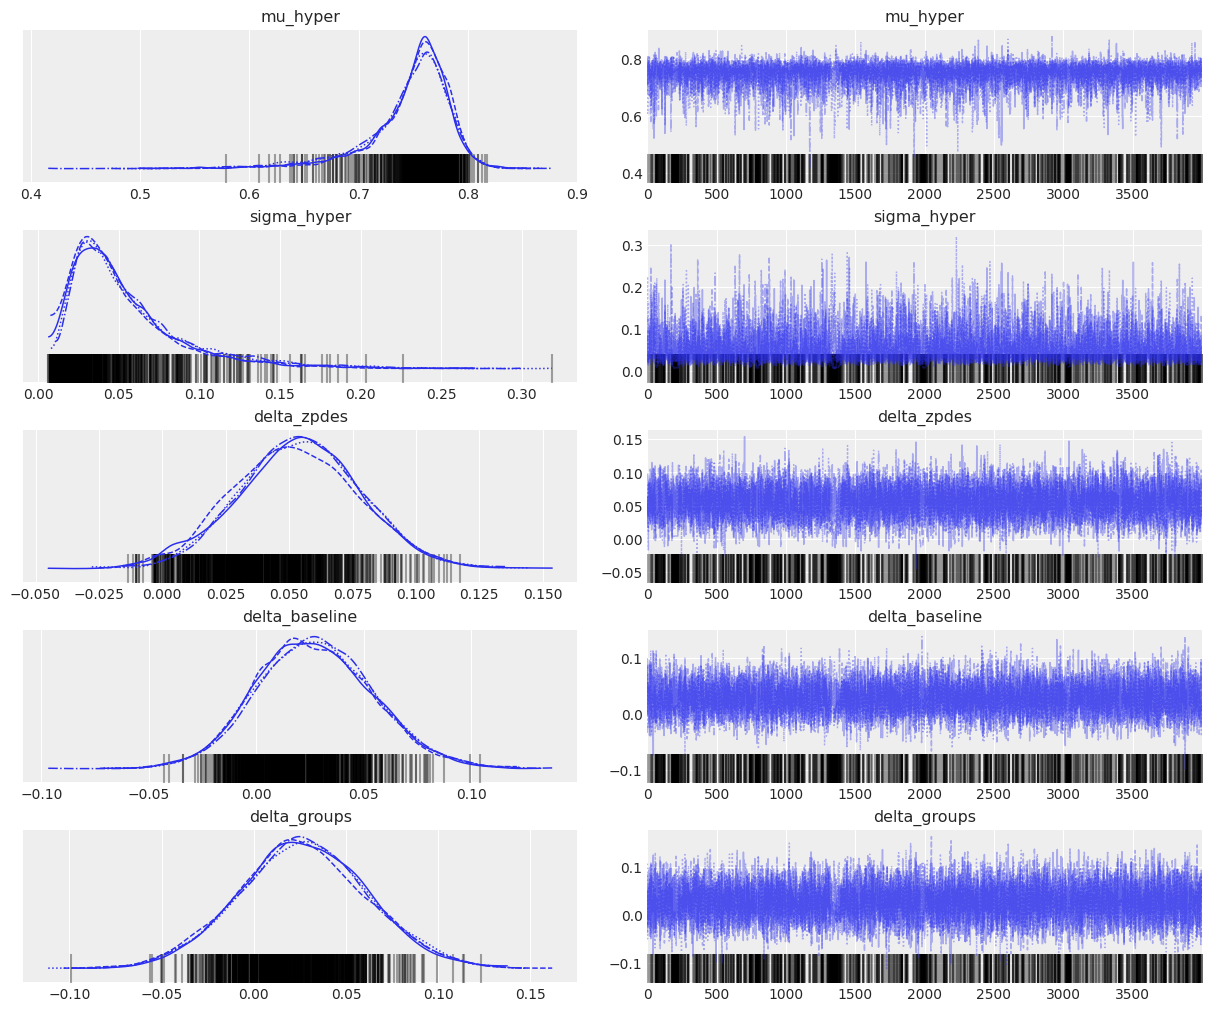

In [293]:
with pm.Model(coords=coords) as accuracy_model:
    # Hyperpriors for population mean and standard deviation
    mu_hyper = pm.Normal('mu_hyper', mu=0.5, sigma=0.1)
    sigma_hyper = pm.HalfNormal('sigma_hyper', 0.1)
    
    # Data
    g = pm.MutableData("g", data_combined.condition_idx, dims="obs_id")
    t = pm.MutableData("t", data_combined.time_idx, dims="obs_id")
    
    # Participant-level means
    mu = pm.Normal('mu', mu=mu_hyper, sigma=sigma_hyper, dims=("condition", "time"))
    
    # Deterministic parameters for the differences
    delta_zpdes = pm.Deterministic("delta_zpdes", mu[1, 1] - mu[1, 0])  # post - pre for zpdes
    delta_baseline = pm.Deterministic("delta_baseline", mu[0, 1] - mu[0, 0])  # post - pre for baseline
    delta_groups = pm.Deterministic("delta_groups", delta_zpdes - delta_baseline)
    
    # Common standard deviation for all participants
    sigma = pm.HalfNormal('sigma', 0.1, dims=("condition", "time"))
    
    # likelihood
    pm.Normal("y", mu=mu[g,t], sigma=sigma[g,t], observed=data.y, dims="obs_id")

with accuracy_model:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace, var_names=["mu_hyper", "sigma_hyper", "delta_zpdes", "delta_baseline", "delta_groups"])
az.summary(trace)
pm.model_to_graphviz(hierarchical_model)
plt.show()

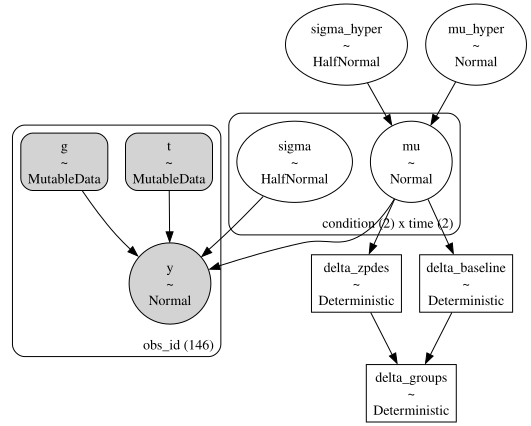

In [294]:
pm.model_to_graphviz(accuracy_model)

In [295]:
data_combined

,task_status,condition,3-nb-targets-accuracy_continuous,5-nb-targets-accuracy_continuous,3-nb-targets-correct,5-nb-targets-correct,3-nb-targets-nb,5-nb-targets-nb,condition_idx,time_idx
participant_id,,,,,,,,,,
594,PRE_TEST,zpdes,0.827160,0.755556,17,11,27,27,1,0
595,PRE_TEST,zpdes,0.753086,0.651852,13,2,27,27,1,0
596,PRE_TEST,baseline,0.629630,0.600000,8,3,27,27,0,0
597,PRE_TEST,baseline,0.839506,0.770370,19,7,27,27,0,0
599,PRE_TEST,zpdes,0.358025,0.562963,3,3,27,27,1,0
...,...,...,...,...,...,...,...,...,...,...
672,POST_TEST,baseline,0.802469,0.659259,16,5,27,27,0,1
674,POST_TEST,zpdes,0.851852,0.777778,16,9,27,27,1,1
676,POST_TEST,baseline,0.876543,0.785185,21,13,27,27,0,1


In [327]:
study = "v3_prolific"
task = "taskswitch"
path = f"../outputs/{study}/results_{study}/{task}"
df = pd.read_csv(f'{path}/{task}_lfa.csv')

In [328]:
df =df[["participant_id", "task_status","condition", "switch_indicator", "results_rt"]]
from ast import literal_eval

In [329]:
df['switch_indicator'] = df.apply(lambda row: literal_eval(row['switch_indicator']), axis=1)
df['results_rt'] = df.apply(lambda row: literal_eval(row['results_rt']), axis=1)

In [330]:
df

,participant_id,task_status,condition,switch_indicator,results_rt
0,594,PRE_TEST,zpdes,"[0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, ...","[1401, 559, 1013, 611, 1028, 1600, 1241, 1742,..."
1,594,POST_TEST,zpdes,"[0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, ...","[1150, 566, 450, 849, 998, 549, 481, 767, 866,..."
2,595,PRE_TEST,zpdes,"[0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, ...","[3750, 1300, 783, 866, 1116, 1350, 1234, 983, ..."
3,595,POST_TEST,zpdes,"[1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, ...","[900, 967, 1066, 833, 616, 750, 650, 616, 717,..."
4,596,PRE_TEST,baseline,"[1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, ...","[3483, 1417, 1733, 1300, 1616, 916, 1016, 1317..."
...,...,...,...,...,...
141,676,POST_TEST,baseline,"[0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, ...","[950, 732, 651, 1366, 1133, 850, 616, 900, 899..."
142,677,PRE_TEST,baseline,"[1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, ...","[4806, 833, 584, 611, 3042, 375, 361, 375, 402..."
143,677,POST_TEST,baseline,"[1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, ...","[1250, 916, 666, 1083, 1376, 875, 1000, 1167, ..."
144,679,PRE_TEST,baseline,"[1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, ...","[1183, 566, 701, 517, 549, 717, 582, 1265, 516..."


In [331]:
df['nb_trials'] = df.apply(lambda row: len(row['switch_indicator']), axis=1)

In [333]:
conditions = ["zpdes", "baseline"]
times = ["pre", "post"]

# Create 'condition' and 'time' indices
data_pre = df[df["task_status"]=="PRE_TEST"]
data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
data_pre['time_idx'] = 0  # 0 for 'pre'
data_post = df[df["task_status"]=="POST_TEST"]
data_post['condition_idx'] = (data_post['condition'] == 'zpdes').astype(int)
data_post['time_idx'] = 1  # 1 for 'post'
data_pre = data_pre.set_index('participant_id')
data_post = data_post.set_index('participant_id')

# Merge data_pre and data_post into one dataframe
data_combined = pd.concat([data_pre, data_post], axis=0)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/1832770716.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['condition_idx'] = (data_pre['condition'] == 'zpdes').astype(int)
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/1832770716.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['time_idx'] = 0  # 0 for 'pre'
/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_59296/1832770716.py:9: SettingWithCopyWarning: 
A value is trying to be set on a c

In [335]:
coords = {"condition": conditions, "time": times, "switch_indicator": ["switch", "unswitch"]}

In [340]:
# Transform the dataframe
rows = []
for idx, row in data_combined.iterrows():
    for rt, switch in zip(row['results_rt'], row['switch_indicator']):
        rows.append({
            'participant_id': idx,
            'task_status': row['task_status'],
            'condition': row['condition'],
            'results_rt': rt,
            'switch_indicator': switch,
            'nb_trials': row['nb_trials'],
            'condition_idx': row['condition_idx'],
            'time_idx': row['time_idx']
        })
df_transformed = pd.DataFrame(rows)

In [341]:
df_transformed

,participant_id,task_status,condition,results_rt,switch_indicator,nb_trials,condition_idx,time_idx
0,594,PRE_TEST,zpdes,1401,0,99,1,0
1,594,PRE_TEST,zpdes,559,0,99,1,0
2,594,PRE_TEST,zpdes,1013,1,99,1,0
3,594,PRE_TEST,zpdes,611,1,99,1,0
4,594,PRE_TEST,zpdes,1028,0,99,1,0
...,...,...,...,...,...,...,...,...
14299,679,POST_TEST,baseline,819,0,99,0,1
14300,679,POST_TEST,baseline,1820,1,99,0,1
14301,679,POST_TEST,baseline,1389,1,99,0,1
14302,679,POST_TEST,baseline,1584,0,99,0,1


In [354]:
with pm.Model(coords=coords) as switching_cost_RT:
    # Data
    g = pm.MutableData("g", df_transformed.condition_idx, dims="obs_id")
    t = pm.MutableData("t", df_transformed.time_idx, dims="obs_id")
    s = pm.MutableData("s", df_transformed.switch_indicator, dims="obs_id")

    # Hyperpriors for group means
    mu_hyper_mean = pm.Normal('mu_hyper_mean', mu=0, sigma=10)
    mu_hyper_sd = pm.HalfNormal('mu_hyper_sd', sigma=10)

    # Hyperpriors for group standard deviations
    sigma_hyper_sd = pm.HalfNormal('sigma_hyper_sd', sigma=10)

    # Priors for group means given the hyperpriors
    mu = pm.Normal('mu', mu=mu_hyper_mean, sigma=mu_hyper_sd,  dims=("condition", "time", "switch_indicator"))

    # Priors for group standard deviations given the hyperpriors
    sigma = pm.HalfNormal('sigma', sigma=sigma_hyper_sd, dims=("condition", "time", "switch_indicator"))

    # Likelihood for each observation
    rt_obs = pm.Normal('rt_obs', mu=mu[g,t,s],
                       sigma=sigma[g,t,s], observed=df_transformed["results_rt"])

    # Deterministic node for switching cost
    switching_cost = pm.Deterministic('switching_cost', mu[:,:,1] - mu[:,:,0])

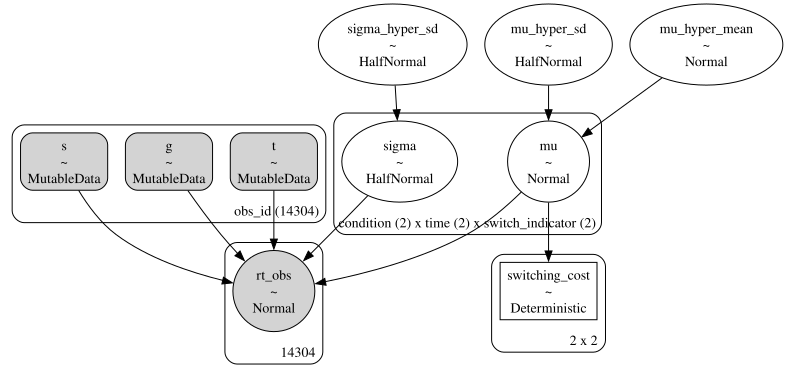

In [355]:
pm.model_to_graphviz(switching_cost_RT)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_hyper_mean, mu_hyper_sd, sigma_hyper_sd, mu, sigma]


Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 163 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_hyper_mean,28.699,10.086,9.441,47.103,0.055,0.043,33177.0,12539.0,1.0
"mu[zpdes, pre, switch]",862.500,11.785,841.409,885.524,0.064,0.045,33979.0,12786.0,1.0
"mu[zpdes, pre, unswitch]",868.529,12.266,846.191,892.315,0.067,0.047,33610.0,11930.0,1.0
"mu[zpdes, post, switch]",901.882,13.511,876.158,926.884,0.076,0.054,31696.0,11678.0,1.0
"mu[zpdes, post, unswitch]",865.081,11.801,842.930,887.318,0.064,0.045,33623.0,12219.0,1.0
"mu[baseline, pre, switch]",883.148,10.727,861.627,902.191,0.061,0.043,31086.0,11870.0,1.0
"mu[baseline, pre, unswitch]",872.578,11.208,851.562,893.584,0.060,0.042,35036.0,11542.0,1.0
"mu[baseline, post, switch]",847.280,10.618,827.792,867.770,0.056,0.040,35505.0,11462.0,1.0
"mu[baseline, post, unswitch]",851.513,9.861,833.263,869.981,0.053,0.038,34093.0,11705.0,1.0
mu_hyper_sd,153.117,5.136,143.882,163.013,0.028,0.020,32617.0,12180.0,1.0


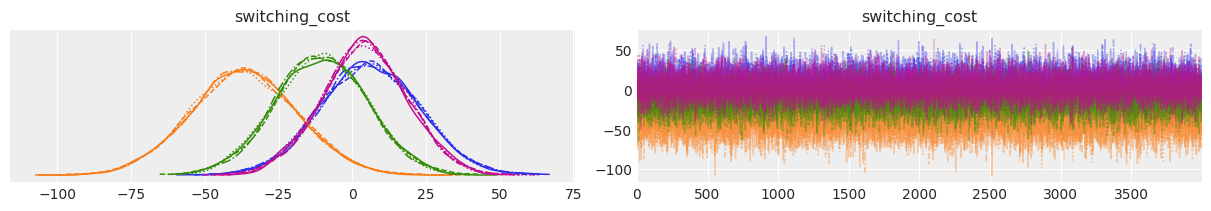

In [356]:
with switching_cost_RT:
    trace = pm.sample(4000, idata_kwargs={'log_likelihood': True})

az.plot_trace(trace, var_names=["switching_cost"])
az.summary(trace)

array([[<Axes: title={'center': 'switching_cost'}>,
        <Axes: title={'center': 'switching_cost'}>]], dtype=object)

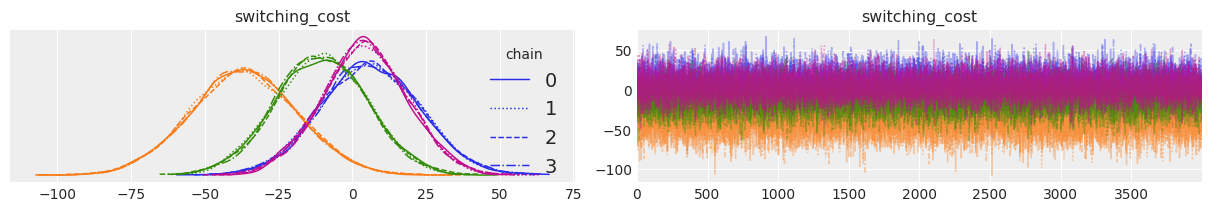

In [357]:
az.plot_trace(trace, var_names=["switching_cost"], legend=True)

In [362]:
study="v3_prolific"
task="enumeration"
path_study = f"../outputs/{study}/results_{study}/"
path = f"{path_study}/{task}"
path_to_store = f"{path}/outputs"
task_condition1, task_condition2 = "5", "6"
model = "hierarbinom"
trace1 = az.from_json(f"{path_to_store}/{task_condition1}-{model}_inference_data.json")
trace2 = az.from_json(f"{path_to_store}/{task_condition2}-{model}_inference_data.json")

In [364]:
trace2

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data
	> constant_data

In [373]:
posterior1 = trace1.posterior
posterior2 = trace2.posterior

# Step 2: Calculate the differences
# This assumes that the two posteriors have the same dimensions and coordinate names
diff = posterior1 - posterior2
az.summary(diff)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
"beta[zpdes, pre]",0.118,0.052,0.019,0.214,0.000,0.000,18806.0,13704.0,1.0
"beta[zpdes, post]",0.113,0.056,0.008,0.218,0.000,0.000,19361.0,13685.0,1.0
"beta[baseline, pre]",0.064,0.049,-0.033,0.151,0.000,0.000,19143.0,13770.0,1.0
"beta[baseline, post]",0.088,0.054,-0.007,0.194,0.000,0.000,18073.0,14238.0,1.0
"sigma[zpdes, pre]",0.011,0.033,-0.053,0.072,0.000,0.000,12531.0,13250.0,1.0
...,...,...,...,...,...,...,...,...,...
p_observation[144],0.152,0.120,-0.081,0.370,0.001,0.001,24152.0,14063.0,1.0
p_observation[145],0.022,0.132,-0.215,0.279,0.001,0.001,25331.0,13837.0,1.0
delta_zpdes,0.025,0.072,-0.112,0.160,0.001,0.000,18383.0,14576.0,1.0
delta_baseline,-0.005,0.077,-0.146,0.143,0.001,0.001,18919.0,13961.0,1.0


In [372]:
plt.show()